# Tiamat — Comparação e seleção na validação

O objetivo é comparar os cinco pipelines otimizados nas partidas oficiais de validação. A metodologia dos pipelines segue a [documentação do scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html).


In [1]:
from pathlib import Path
import hashlib
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import optuna
from IPython.display import display, Markdown
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

SEED = 210906
LANCE = 40
MIN_CONFIGURACOES = 100
MODELOS = ['Regressao_Logistica', 'Random_Forest', 'Gradient_Boosting', 'XGBoost', 'SVM']
ATRIBUTOS = [
    'rank_b', 'rank_w', 'komi', 'handicap',
    'maior_grupo_b', 'maior_grupo_w',
    'liberdades_maior_grupo_b', 'liberdades_maior_grupo_w',
    'pedras_em_jogo_b', 'pedras_em_jogo_w',
    'pedras_capturadas_por_b', 'pedras_capturadas_por_w',
    'distancia_media_tengen_b', 'distancia_media_tengen_w',
    'quantidade_grupos_b', 'quantidade_grupos_w',
    'tamanho_medio_grupos_b', 'tamanho_medio_grupos_w',
    'liberdades_medias_grupos_b', 'liberdades_medias_grupos_w',
    'grupos_em_atari_b', 'grupos_em_atari_w',
    'pedras_em_atari_b', 'pedras_em_atari_w'
]
CANDIDATOS = [Path('data/piloto_final/lance_040.csv'),
    Path('data/piloto_corrigido/lance_040.csv'), Path('data/piloto/lance_040.csv'),
    Path('data/processed/lance_040.csv'), Path('lance_040.csv')]
ARQUIVO_CSV = next((p for p in CANDIDATOS if p.exists()), None)
if ARQUIVO_CSV is None:
    raise FileNotFoundError('Ajuste CANDIDATOS para localizar o mesmo CSV usado no notebook 03.')
PASTA = Path('results/lance_040')
PASTA.mkdir(parents=True, exist_ok=True)
FIGURAS = PASTA / 'figuras'
FIGURAS.mkdir(exist_ok=True)

def sha256_arquivo(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def ler_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def salvar_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2,
        allow_nan=False), encoding='utf-8')

def carregar_dados(split):
    dados = pd.read_csv(ARQUIVO_CSV)
    dados = dados.loc[dados['split'].eq(split)].copy()
    if not len(dados):
        raise ValueError(f'Conjunto {split} vazio.')
    assert dados.game_id.is_unique
    assert dados.lance.eq(LANCE).all()
    assert dados.vencedor.isin(['B', 'W']).all()
    return dados

def separar_xy(dados):
    X = dados[ATRIBUTOS].apply(pd.to_numeric, errors='raise')
    y = dados.vencedor.map({'B': 0, 'W': 1}).astype(int)
    assert not np.isinf(X.to_numpy()).any()
    return X, y

def pontuacoes(modelo, X):
    if hasattr(modelo, 'predict_proba'):
        classe_w = list(modelo.classes_).index(1)
        return modelo.predict_proba(X)[:, classe_w], 'probabilidade_W'
    return np.asarray(modelo.decision_function(X)).ravel(), 'margem_W'

def metricas_predicoes(y, pred, score):
    y = np.asarray(y)
    return {'n': int(len(y)), 'accuracy': float(accuracy_score(y, pred)),
        'balanced_accuracy': float(balanced_accuracy_score(y, pred)),
        'f1_macro': float(f1_score(y, pred, average='macro', zero_division=0)),
        'roc_auc': float(roc_auc_score(y, score)) if len(np.unique(y)) == 2 else np.nan}

def avaliar_modelo(modelo, dados):
    X, y = separar_xy(dados)
    pred = modelo.predict(X)
    score, tipo = pontuacoes(modelo, X)
    tabela = pd.DataFrame({'game_id': dados.game_id.to_numpy(),
        'y_real': y.to_numpy(), 'y_pred': pred, 'score_W': score,
        'tipo_score': tipo, 'acertou': pred == y.to_numpy()})
    return metricas_predicoes(y, pred, score), tabela

def carregar_estudos():
    estudos, linhas = {}, []
    for nome in MODELOS:
        db = (PASTA / f'optuna_{nome}.db').resolve()
        distintos = completos = 0
        melhor = np.nan
        if db.exists():
            # Mesmo nome de estudo e formato SQLite do notebook 03 antigo.
            estudo = optuna.load_study(study_name=f'tiamat_lance40_{nome}',
                storage=f'sqlite:///{db.as_posix()}')
            estudos[nome] = estudo
            trials = [t for t in estudo.trials
                if t.state == optuna.trial.TrialState.COMPLETE and t.value is not None]
            completos = len(trials)
            distintos = len({json.dumps(t.params, sort_keys=True) for t in trials})
            if completos:
                melhor = float(estudo.best_value)
        resumo_path = PASTA / f'resumo_{nome}.json'
        if resumo_path.exists():
            resumo = ler_json(resumo_path)
            if (resumo.get('seed') != SEED or resumo.get('lance') != LANCE
                    or resumo.get('folds') != 5):
                raise ValueError(f'Resumo de {nome} incompatível com o protocolo do 03 antigo.')
        linhas.append({'modelo': nome, 'configuracoes_distintas': distintos,
            'trials_completos': completos, 'roc_auc_cv': melhor,
            'pronto': distintos >= MIN_CONFIGURACOES})
    return estudos, pd.DataFrame(linhas)

def carregar_selecionado():
    selecao = ler_json(PASTA / 'selecao_congelada.json')
    if selecao.get('origem') != '03_antigo':
        raise ValueError('A seleção existente não foi produzida por esta sequência compatível.')
    if selecao['sha256_csv'] != sha256_arquivo(ARQUIVO_CSV):
        raise ValueError('O CSV foi alterado após a seleção. Preserve os dados desta execução.')
    path = PASTA / selecao['arquivo_modelo']
    if selecao['sha256_modelo'] != sha256_arquivo(path):
        raise ValueError('O modelo selecionado foi alterado após o congelamento.')
    return joblib.load(path), selecao

print('CSV:', ARQUIVO_CSV, '| resultados:', PASTA)
print('SEED:', SEED, '| 24 atributos | compatível com o notebook 03 original')


CSV: data\piloto_final\lance_040.csv | resultados: results\lance_040
SEED: 210906 | 24 atributos | compatível com o notebook 03 original


## 1. Conferir os estudos antigos

Esta célula apenas carrega estudos existentes. Mantém os nomes, os parâmetros e a contagem de configurações do 03. Nenhuma nova otimização é iniciada.


In [2]:
estudos, status = carregar_estudos()
display(status)
status.to_csv(PASTA / 'status_estudos.csv', index=False)
PRONTO = bool(status.pronto.all())
print('Pronto para comparar na validação:', PRONTO)
if not PRONTO:
    print('Termine as buscas do notebook 03. As células seguintes aguardarão seus resultados.')


,modelo,configuracoes_distintas,trials_completos,roc_auc_cv,pronto
0,Regressao_Logistica,100,100,0.562428,True
1,Random_Forest,100,100,0.555193,True
2,Gradient_Boosting,100,100,0.563409,True
3,XGBoost,100,100,0.562010,True
4,SVM,100,100,0.561449,True


Pronto para comparar na validação: True


## 2. Comparar os resultados da busca

O notebook 3 registra a média e o desvio padrão de ROC-AUC e a média de balanced accuracy. Ele não salva todas as métricas por fold. A comparação abaixo usa os valores que realmente existem; o desempenho do melhor trial pode ser otimista devido à seleção dos hiperparâmetros.


,modelo,roc_auc_cv,dp_roc_auc_cv,balanced_accuracy_cv
2,Gradient_Boosting,0.563409,0.012874,0.544721
0,Regressao_Logistica,0.562428,0.021505,0.546533
3,XGBoost,0.562010,0.014717,0.549721
4,SVM,0.561449,0.021433,0.544680
1,Random_Forest,0.555193,0.017908,0.549283


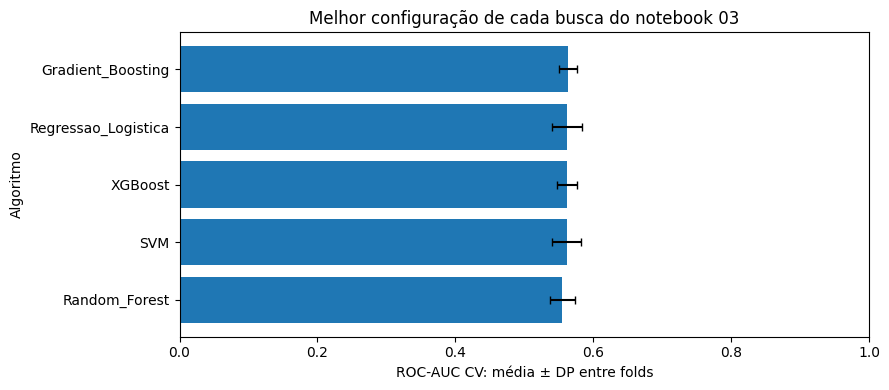

In [3]:
linhas_cv = []
for nome, estudo in estudos.items():
    if any(t.state == optuna.trial.TrialState.COMPLETE for t in estudo.trials):
        t = estudo.best_trial
        linhas_cv.append({'modelo': nome, 'roc_auc_cv': t.value,
            'dp_roc_auc_cv': t.user_attrs.get('cv_std_roc_auc', np.nan),
            'balanced_accuracy_cv': t.user_attrs.get('cv_mean_bal_acc', np.nan)})
cv_tab = pd.DataFrame(linhas_cv)
if len(cv_tab):
    display(cv_tab.sort_values('roc_auc_cv', ascending=False))
    cv_tab.to_csv(PASTA / 'comparacao_cv.csv', index=False)
    ordem = cv_tab.sort_values('roc_auc_cv')
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.barh(ordem.modelo, ordem.roc_auc_cv,
        xerr=ordem.dp_roc_auc_cv.fillna(0), capsize=3)
    ax.set(xlabel='ROC-AUC CV: média ± DP entre folds', ylabel='Algoritmo',
        xlim=(0, 1), title='Melhor configuração de cada busca do notebook 03')
    fig.tight_layout(); fig.savefig(FIGURAS / '04_comparacao_cv.png', dpi=180)
    plt.show()
else:
    print('Ainda não há resultados de CV disponíveis.')


## 3. Reconstruir os mesmos pipelines

A função `FixedTrial` recupera seus melhores hiperparâmetros. Os pipelines serão ajustados somente em `train`, com imputação e seleção dentro do pipeline. Não é necessário habilitar `SALVAR_MODELOS` no 03 para esta etapa funcionar.


In [4]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from xgboost import XGBClassifier

MODELOS = [
    'Regressao_Logistica', 'Random_Forest', 'Gradient_Boosting',
    'XGBoost', 'SVM'
]

def construir_pipeline(nome, trial):
    k = trial.suggest_categorical('select_k', [10, 15, 20, 24])
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if nome in {'Regressao_Logistica', 'SVM'}:
        steps.append(('scaler', StandardScaler()))
    steps.append(('select', SelectKBest(score_func=f_classif, k=k)))

    if nome == 'Regressao_Logistica':
        penalty = trial.suggest_categorical('penalty', ['l1', 'l2'])
        model = LogisticRegression(
            C=trial.suggest_float('C', 1e-3, 1e3, log=True),
            penalty=penalty, solver='liblinear', max_iter=3000,
            random_state=SEED
        )
    elif nome == 'Random_Forest':
        model = RandomForestClassifier(
            n_estimators=trial.suggest_int('n_estimators', 150, 600, step=50),
            max_depth=trial.suggest_int('max_depth', 3, 24),
            min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 15),
            min_samples_split=trial.suggest_int('min_samples_split', 2, 20),
            max_features=trial.suggest_float('max_features', 0.4, 1.0),
            random_state=SEED, n_jobs=1
        )
    elif nome == 'Gradient_Boosting':
        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int('n_estimators', 100, 500, step=50),
            learning_rate=trial.suggest_float('learning_rate', 0.015, 0.2, log=True),
            max_depth=trial.suggest_int('max_depth', 1, 4),
            min_samples_leaf=trial.suggest_int('min_samples_leaf', 2, 20),
            subsample=trial.suggest_float('subsample', 0.65, 1.0),
            random_state=SEED
        )
    elif nome == 'XGBoost':
        model = XGBClassifier(
            objective='binary:logistic', eval_metric='logloss',
            n_estimators=trial.suggest_int('n_estimators', 150, 600, step=50),
            learning_rate=trial.suggest_float('learning_rate', 0.015, 0.2, log=True),
            max_depth=trial.suggest_int('max_depth', 2, 8),
            min_child_weight=trial.suggest_int('min_child_weight', 1, 12),
            subsample=trial.suggest_float('subsample', 0.65, 1.0),
            colsample_bytree=trial.suggest_float('colsample_bytree', 0.65, 1.0),
            reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 20, log=True),
            tree_method='hist', random_state=SEED, n_jobs=1
        )
    elif nome == 'SVM':
        kernel = trial.suggest_categorical('kernel', ['linear', 'rbf'])
        kwargs = dict(
            kernel=kernel, C=trial.suggest_float('C', 1e-3, 1e3, log=True),
            cache_size=512, probability=False, random_state=SEED
        )
        if kernel == 'rbf':
            kwargs['gamma'] = trial.suggest_float('gamma', 1e-4, 1.0, log=True)
        model = SVC(**kwargs)
    else:
        raise ValueError(f'Modelo desconhecido: {nome}')
    return Pipeline(steps + [('model', model)])


## 4. Comparar em val e congelar a escolha

A regra é maior ROC-AUC na validação; em caso de empate exato, maior ROC-AUC CV e depois nome alfabético. O Dummy é referência. Para SVM, ROC-AUC usa a margem de decisão; as demais métricas usam `predict` do pipeline.

A escolha é salva em `selecao_congelada.json` e `pipeline_selecionado.joblib`. Reexecuções reutilizam a seleção, sem escolher novamente. Encerre a otimização no 03 antes desta etapa e preserve os arquivos selecionados até terminar a avaliação final.


In [5]:
comparacao = pd.DataFrame()
selecao = None
if PRONTO:
    congelado = PASTA / 'selecao_congelada.json'
    if congelado.exists():
        _, selecao = carregar_selecionado()
        comparacao = pd.read_csv(PASTA / 'comparacao_validacao.csv')
        print('Reutilizando a seleção registrada anteriormente.')
    else:
        treino = carregar_dados('train')
        val = carregar_dados('val')
        assert set(treino.game_id).isdisjoint(val.game_id)
        X_train, y_train = separar_xy(treino)
        pipelines, linhas = {}, []
        for nome in MODELOS:
            estudo = estudos[nome]
            pipeline = construir_pipeline(nome, optuna.trial.FixedTrial(estudo.best_params))
            inicio = time.perf_counter()
            pipeline.fit(X_train, y_train)
            tempo = time.perf_counter() - inicio
            metricas, predicoes = avaliar_modelo(pipeline, val)
            predicoes.to_csv(PASTA / f'predicoes_val_{nome}.csv', index=False)
            joblib.dump(pipeline, PASTA / f'pipeline_{nome}.joblib')
            pipelines[nome] = pipeline
            linhas.append({'modelo': nome, **metricas,
                'roc_auc_cv': float(estudo.best_value), 'fit_treino_s': tempo})
        dummy = Pipeline([('imputer', SimpleImputer(strategy='median')),
            ('model', DummyClassifier(strategy='prior'))])
        dummy.fit(X_train, y_train)
        m_dummy, p_dummy = avaliar_modelo(dummy, val)
        p_dummy.to_csv(PASTA / 'predicoes_val_Dummy_prior.csv', index=False)
        joblib.dump(dummy, PASTA / 'pipeline_Dummy_prior.joblib')
        linhas.append({'modelo': 'Dummy_prior', **m_dummy,
            'roc_auc_cv': 0.5, 'fit_treino_s': np.nan})
        comparacao = pd.DataFrame(linhas)
        ordem = comparacao[comparacao.modelo.isin(MODELOS)].sort_values(
            ['roc_auc', 'roc_auc_cv', 'modelo'], ascending=[False, False, True])
        escolhido = ordem.iloc[0]['modelo']
        modelo_path = PASTA / 'pipeline_selecionado.joblib'
        joblib.dump(pipelines[escolhido], modelo_path)
        selecao = {'origem': '03_antigo', 'modelo': escolhido, 'seed': SEED,
            'lance': LANCE, 'atributos': ATRIBUTOS,
            'melhores_parametros': estudos[escolhido].best_params,
            'regra': 'Maior ROC-AUC em val; empate: ROC-AUC CV; depois nome.',
            'ajustado_em': 'train', 'n_treino': len(treino), 'n_val': len(val),
            'arquivo_modelo': modelo_path.name,
            'sha256_modelo': sha256_arquivo(modelo_path),
            'arquivo_dummy': 'pipeline_Dummy_prior.joblib',
            'sha256_dummy': sha256_arquivo(PASTA / 'pipeline_Dummy_prior.joblib'),
            'sha256_csv': sha256_arquivo(ARQUIVO_CSV),
            'limiar': 0.0 if escolhido == 'SVM' else 0.5}
        comparacao.to_csv(PASTA / 'comparacao_validacao.csv', index=False)
        salvar_json(congelado, selecao)
    display(comparacao.sort_values('roc_auc', ascending=False).round(4))
    print('Modelo selecionado:', selecao['modelo'])
    print('Ajustado somente em:', selecao['ajustado_em'])
else:
    print('Sem comparação em val enquanto as cinco buscas estiverem incompletas.')


,modelo,n,accuracy,balanced_accuracy,f1_macro,roc_auc,roc_auc_cv,fit_treino_s
1,Random_Forest,270,0.5778,0.5778,0.5778,0.6083,0.5552,10.7720
0,Regressao_Logistica,270,0.5556,0.5557,0.5556,0.5757,0.5624,0.2379
3,XGBoost,270,0.5185,0.5184,0.5184,0.5687,0.5620,0.4953
4,SVM,270,0.5407,0.5406,0.5406,0.5659,0.5614,12.7935
2,Gradient_Boosting,270,0.5593,0.5588,0.5585,0.5623,0.5634,2.7641
5,Dummy_prior,270,0.4926,0.5000,0.3300,0.5000,0.5000,NaN


Modelo selecionado: Random_Forest
Ajustado somente em: train


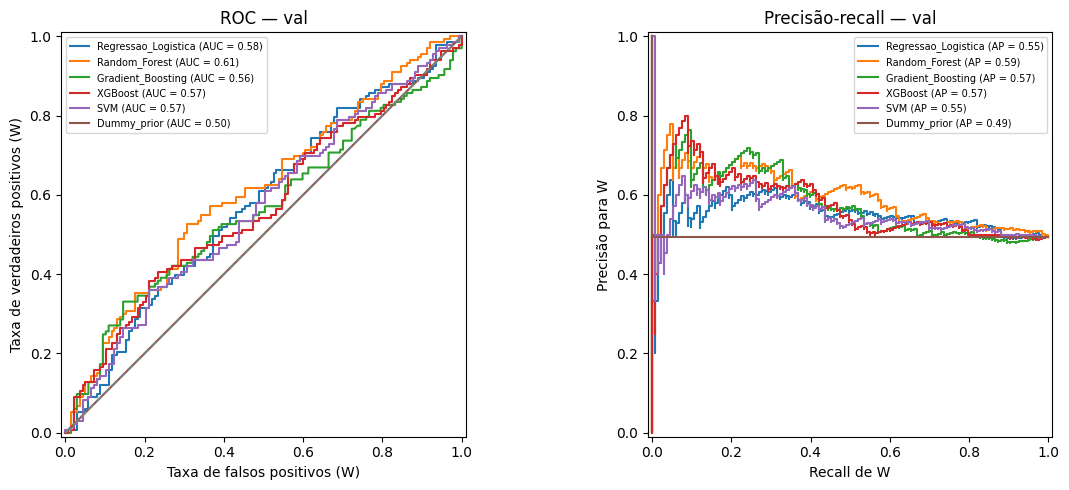

modelo,Gradient_Boosting,Random_Forest,Regressao_Logistica,SVM,XGBoost
atributo,,,,,
distancia_media_tengen_b,True,True,True,True,True
distancia_media_tengen_w,True,True,True,True,True
grupos_em_atari_b,True,True,True,True,True
grupos_em_atari_w,True,True,True,True,True
handicap,True,True,True,True,True
komi,True,True,True,True,True
liberdades_maior_grupo_b,True,True,True,True,True
liberdades_maior_grupo_w,True,True,True,True,True
liberdades_medias_grupos_b,True,True,True,True,True


In [6]:
if selecao is not None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    atributos_linhas = []
    for nome in [*MODELOS, 'Dummy_prior']:
        p = pd.read_csv(PASTA / f'predicoes_val_{nome}.csv')
        RocCurveDisplay.from_predictions(p.y_real, p.score_W, name=nome, ax=axes[0])
        PrecisionRecallDisplay.from_predictions(p.y_real, p.score_W, name=nome, ax=axes[1])
        if nome in MODELOS:
            pipe = joblib.load(PASTA / f'pipeline_{nome}.joblib')
            atributos_linhas.extend({'modelo': nome, 'atributo': c, 'selecionado': bool(v)}
                for c, v in zip(ATRIBUTOS, pipe.named_steps['select'].get_support()))
    axes[0].plot([0, 1], [0, 1], '--', color='gray')
    axes[0].set(xlabel='Taxa de falsos positivos (W)', ylabel='Taxa de verdadeiros positivos (W)', title='ROC — val')
    axes[1].set(xlabel='Recall de W', ylabel='Precisão para W', title='Precisão-recall — val')
    for ax in axes: ax.legend(fontsize=7)
    fig.tight_layout(); fig.savefig(FIGURAS / '04_curvas_validacao.png', dpi=180)
    plt.show()
    atributos_selecionados = pd.DataFrame(atributos_linhas)
    atributos_selecionados.to_csv(PASTA / 'atributos_selecionados.csv', index=False)
    display(atributos_selecionados.pivot(index='atributo', columns='modelo', values='selecionado'))


## Análise

O ranking mudou Gradient Boosting liderou a CV (0,5634), enquanto Random Forest liderou a validação (0,6083), com 270 partidas frente às 4.612 do treino.  
O Random Forest superou o Dummy em 0,1083 e a regressão logística em 0,0326 de ROC-AUC, sem demonstrar superioridade estatística conclusiva.  
Todos mantiveram 24 atributos; da CV para val, diminuíram a AUC do Gradient Boosting e a balanced accuracy do XGBoost e da SVM.  
Como a validação participou da escolha, ela deixou de representar uma avaliação final independente.

## Conclusões e principais aprendizados

O Random Forest foi selecionado pela maior ROC-AUC na validação, de 0,6083, após 100 configurações distintas completas por algoritmo.  
Sua accuracy, balanced accuracy e F1-macro foram aproximadamente 0,5778, todas superiores ao Dummy.  
O desempenho permanece modesto e precisa ser examinado considerando o tamanho da validação e a incerteza amostral.  
A explicabilidade será investigada no notebook 05, e a avaliação no teste reservado ocorrerá somente no 06.

## Descrição do uso de IA neste trabalho

O ChatGPT auxiliou na implementação das comparações, na reconstrução dos pipelines e na organização do notebook.  
Também apoiou a interpretação das métricas, das mudanças no ranking e da seleção de atributos.  


## Referências consultadas

- Cassar, D. R. *Criaturas Lendárias do Reino de Lumi e onde encontrá-las*, ATP-203, seção Tiamat. Material da disciplina.
- [Joe's Go Database — origem dos SGFs](https://www.pjreddie.com/projects/jgdb/).
- [scikit-learn — pipelines e prevenção de vazamento](https://scikit-learn.org/stable/common_pitfalls.html).
- [scikit-learn — métricas de classificação](https://scikit-learn.org/stable/modules/model_evaluation.html).
- [scikit-learn — importância por permutação](https://scikit-learn.org/stable/modules/permutation_importance.html).
- [Optuna — salvamento e retomada de estudos](https://optuna.readthedocs.io/en/stable/tutorial/20_recipes/001_rdb.html).

As referências devem ser citadas junto às explicações em sua discussão. A lista acima não substitui sua leitura.
